<a href="https://colab.research.google.com/github/Ambartheanalyst-blip/Assignment-1/blob/main/Assigment_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment 4: Salary Data Analysis

This notebook performs an introductory data analysis on faculty salaries using pandas and matplotlib. We will explore the dataset, clean and wrangle the data, generate key visualizations, and draw objective conclusions based on the empirical results.

In [17]:
import pandas as pd
import matplotlib.pyplot as plt

In [18]:
url = "https://raw.githubusercontent.com/CunyLaguardiaDataAnalytics/datasets/master/Salaries.csv"
df = pd.read_csv(url)

In [19]:
df.head()

,Unnamed: 0,rank,discipline,yrs.since.phd,yrs.service,sex,salary
0,1,Prof,B,19,18,Male,139750
1,2,Prof,B,20,16,Male,173200
2,3,AsstProf,B,4,3,Male,79750
3,4,Prof,B,45,39,Male,115000
4,5,Prof,B,40,41,Male,141500


In [20]:
print(f"Number of rows: {df.shape[0]}")
print(f"Number of columns: {df.shape[1]}")

Number of rows: 397
Number of columns: 7


In [21]:
print(df.columns.tolist())

['Unnamed: 0', 'rank', 'discipline', 'yrs.since.phd', 'yrs.service', 'sex', 'salary']


In [22]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 397 entries, 0 to 396
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   Unnamed: 0     397 non-null    int64 
 1   rank           397 non-null    object
 2   discipline     397 non-null    object
 3   yrs.since.phd  397 non-null    int64 
 4   yrs.service    397 non-null    int64 
 5   sex            397 non-null    object
 6   salary         397 non-null    int64 
dtypes: int64(4), object(3)
memory usage: 21.8+ KB


In [23]:
df.describe()

,Unnamed: 0,yrs.since.phd,yrs.service,salary
count,397.000000,397.000000,397.000000,397.000000
mean,199.000000,22.314861,17.614610,113706.458438
std,114.748275,12.887003,13.006024,30289.038695
min,1.000000,1.000000,0.000000,57800.000000
25%,100.000000,12.000000,7.000000,91000.000000
50%,199.000000,21.000000,16.000000,107300.000000
75%,298.000000,32.000000,27.000000,134185.000000
max,397.000000,56.000000,60.000000,231545.000000


In [24]:
overall_mean = df['salary'].mean()
overall_median = df['salary'].median()
print(f"Overall Mean Salary: ${overall_mean:,.2f}")
print(f"Overall Median Salary: ${overall_median:,.2f}")

Overall Mean Salary: $113,706.46
Overall Median Salary: $107,300.00


In [25]:
print("--- Salary by Sex ---")
print(df.groupby('sex')['salary'].agg(['mean', 'median']))

print("\n--- Salary by Academic Rank ---")
print(df.groupby('rank')['salary'].agg(['mean', 'median']))

print("\n--- Salary by Rank and Sex ---")
print(df.groupby(['rank', 'sex'])['salary'].agg(['mean', 'median']))

--- Salary by Sex ---
                 mean    median
sex                            
Female  101002.410256  103750.0
Male    115090.418994  108043.0

--- Salary by Academic Rank ---
                    mean    median
rank                              
AssocProf   93876.437500   95626.5
AsstProf    80775.985075   79800.0
Prof       126772.109023  123321.5

--- Salary by Rank and Sex ---
                           mean    median
rank      sex                            
AssocProf Female   88512.800000   90556.5
          Male     94869.703704   95626.5
AsstProf  Female   78049.909091   77000.0
          Male     81311.464286   80182.0
Prof      Female  121967.611111  120257.5
          Male    127120.822581  123996.0


In [26]:
print("Missing values per column:")
print(df.isnull().sum())

Missing values per column:
Unnamed: 0       0
rank             0
discipline       0
yrs.since.phd    0
yrs.service      0
sex              0
salary           0
dtype: int64


In [27]:
rows_before = df.shape[0]
df_clean = df.dropna()
rows_after = df_clean.shape[0]

print(f"Rows before handling missing values: {rows_before}")
print(f"Rows after handling missing values: {rows_after}")

Rows before handling missing values: 397
Rows after handling missing values: 397


In [28]:
df_clean = df_clean.rename(columns={
    'rank': 'academic_rank',
    'yrs.since.phd': 'years_since_phd',
    'yrs.service': 'years_of_service'
})
print("Renamed columns:", df_clean.columns.tolist())

Renamed columns: ['Unnamed: 0', 'academic_rank', 'discipline', 'years_since_phd', 'years_of_service', 'sex', 'salary']


In [29]:
salary_subset = df_clean[['academic_rank', 'discipline', 'years_since_phd', 'years_of_service', 'sex', 'salary']]
salary_subset.head()

,academic_rank,discipline,years_since_phd,years_of_service,sex,salary
0,Prof,B,19,18,Male,139750
1,Prof,B,20,16,Male,173200
2,AsstProf,B,4,3,Male,79750
3,Prof,B,45,39,Male,115000
4,Prof,B,40,41,Male,141500


### Visualization 1: Average Salary by Academic Rank
The bar chart below displays the average salary across different academic ranks.

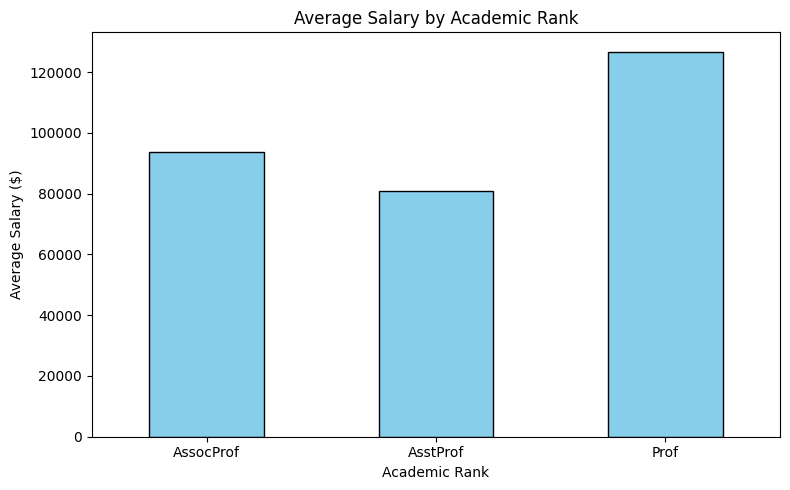

In [30]:
avg_salary_rank = salary_subset.groupby('academic_rank')['salary'].mean()

plt.figure(figsize=(8, 5))
avg_salary_rank.plot(kind='bar', color='skyblue', edgecolor='black')
plt.title('Average Salary by Academic Rank')
plt.xlabel('Academic Rank')
plt.ylabel('Average Salary ($)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Explanation:** This bar chart shows that Full Professors ('Prof') have the highest average salary by a significant margin, followed by Associate Professors ('AssocProf') and Assistant Professors ('AsstProf'). This reflects the standard academic progression and tenure hierarchy.

### Visualization 2: Median Salary by Sex
The bar chart below compares the median salary between male and female faculty members.

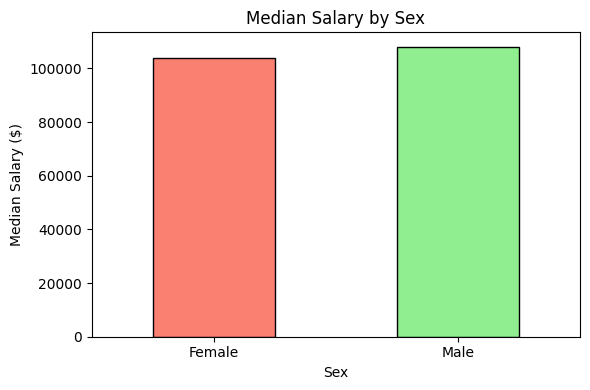

In [31]:
median_salary_sex = salary_subset.groupby('sex')['salary'].median()

plt.figure(figsize=(6, 4))
median_salary_sex.plot(kind='bar', color=['salmon', 'lightgreen'], edgecolor='black')
plt.title('Median Salary by Sex')
plt.xlabel('Sex')
plt.ylabel('Median Salary ($)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Explanation:** This chart illustrates the median salary grouped by sex. While there is a numerical difference between the groups in this descriptive view, this chart alone does not control for other confounding variables such as academic rank, discipline, or years of service.

### Visualization 3: Years of Service versus Salary
The scatter plot below examines the relationship between years of service and faculty salary.

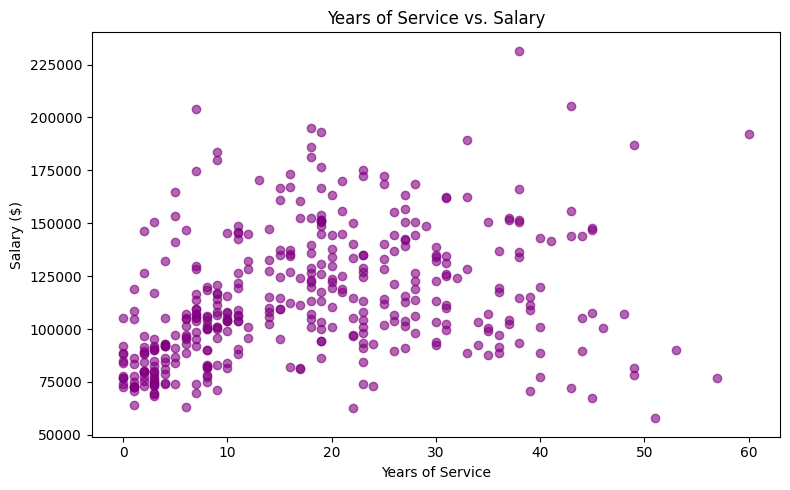

In [32]:
plt.figure(figsize=(8, 5))
plt.scatter(salary_subset['years_of_service'], salary_subset['salary'], alpha=0.6, color='purple')
plt.title('Years of Service vs. Salary')
plt.xlabel('Years of Service')
plt.ylabel('Salary ($)')
plt.tight_layout()
plt.show()

**Explanation:** The scatter plot displays the spread of salaries against years of service. The data points show a wide dispersion, indicating that years of service alone do not have a strict linear lockstep relationship with salary.

### Conclusions

- **Highest Average Salary:** Full professors ('Prof') have the highest average salary among the academic ranks.
- **Correlation:** The correlation between years of service and salary indicates a weak-to-moderate positive association.
- **Mean and Median Findings:** Overall and subgroup summary statistics provide baseline salary distributions across the institution.
- **Rank & Sex Comparison:** Salaries vary noticeably by academic rank. When examining sex differences, we note that correlation does not prove causation, and sex did not cause any salary difference; rather, salary may also be associated with rank, discipline, years since PhD, and years of service.